# Challenge 2: Support Vector Machine and Gradient Boosting

Predict Revenue with two models:

- **Support Vector Machine** (`SVC`, RBF kernel)
- **Gradient Boosting** (`GradientBoostingClassifier`)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (make_scorer, f1_score, precision_score, recall_score, confusion_matrix,
                             roc_auc_score, average_precision_score)

RANDOM_STATE = 42
NAVY, ORANGE, TEAL, RED, GRAY = "#1f3b73", "#f28e2b", "#2a9d8f", "#d1495b", "#9aa0a6"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "font.size": 10,
})

## Load and split

Same code and seed as `challenge2_validation_split.ipynb`.

In [2]:
train = pd.read_csv("challenge2_train.csv")

def to_01(col):
    if col.dtype == bool:
        return col.astype(int)
    return col.astype(str).str.strip().str.lower().map({"true": 1, "false": 0})

y = to_01(train["Revenue"])
X = train.drop(columns=["ID", "Revenue"]).copy()
X["Weekend"] = to_01(X["Weekend"])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
BUYER_SHARE = y_train.mean()
y_true = y_train.to_numpy()

print(f"Training rows: {len(X_train):,} ({BUYER_SHARE:.1%} buyers)")
print(f"Hold-out rows: {len(X_val):,} (not used in this notebook)")

Training rows: 7,397 (15.5% buyers)
Hold-out rows: 1,850 (not used in this notebook)


## Prepare the features

The two models need different preparation with both sitting inside the pipeline.

**Support vector machine** works with distances between rows every input must be on a similar scale. 

**Gradient boosting** is built from decision trees, which only care about the order of values. 

In [3]:
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "PageValues"]
rate_cols = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
bin_cols = ["Weekend"]

assert set(log_cols + rate_cols + cat_cols + bin_cols) == set(X.columns)

scaled_prep = ColumnTransformer([
    ("log", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), log_cols),
    ("rate", StandardScaler(), rate_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

tree_prep = ColumnTransformer([
    ("num", "passthrough", log_cols + rate_cols + bin_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print("Inputs for the SVM:           ", scaled_prep.fit_transform(X_train).shape[1])
print("Inputs for gradient boosting: ", tree_prep.fit_transform(X_train).shape[1])

Inputs for the SVM:            72
Inputs for gradient boosting:  72


## How models are scored

Only 15.5% of visits are purchases. The main score is F1. Also reported: ROC-AUC and PR-AUC, recall, precision, and train F1 with the gap to CV F1.

In [4]:
scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "accuracy": "accuracy",
}

def evaluate(name, prep, model):
    pipe = Pipeline([("prep", prep), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
        row[f"{m} std"] = res[f"test_{m}"].std()
    row["train f1"] = res["train_f1"].mean()
    row["f1 gap"] = row["train f1"] - row["f1"]
    return row

SHOW = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy", "train f1", "f1 gap"]

## Helper functions

The same evaluation steps are needed for both models where they are written once here.

One difference between the models: gradient boosting outputs a probability, while a plain SVC outputs a decision score. Scores work for thresholds just like probabilities the helpers use whichever the model has.

In [5]:
def get_score(model, X_):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

def oof_scores(pipe):
    oof = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        oof[va] = get_score(m, X_train.iloc[va])
    return oof

def threshold_table(oof, grid):
    return pd.DataFrame({
        "threshold": grid,
        "f1": [f1_score(y_true, oof >= t) for t in grid],
        "precision": [precision_score(y_true, oof >= t, zero_division=0) for t in grid],
        "recall": [recall_score(y_true, oof >= t) for t in grid],
    })

def scores_at(oof, t):
    pred = oof >= t
    return {"threshold": t, "f1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "accuracy": (pred == y_true).mean()}

def plot_confusion(oof, thresholds):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    names = ["no purchase", "purchase"]
    for ax, t in zip(axes, thresholds):
        cm = confusion_matrix(y_true, oof >= t)
        share = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=12,
                        color="white" if share[i, j] > 0.5 else "black", fontweight="bold")
        ax.set_xticks([0, 1], names)
        ax.set_yticks([0, 1], names)
        ax.set_xlabel("predicted")
        ax.set_ylabel("actual")
        s = scores_at(oof, t)
        ax.set_title(f"threshold {t:.2f}: F1 {s['f1']:.3f}, recall {s['recall']:.0%}, precision {s['precision']:.0%}",
                     fontsize=10)
    plt.tight_layout()
    plt.show()

def make_summary(name, row, params, thr, at_t):
    return pd.Series({
        "settings": str(params),
        "CV ROC-AUC": round(row["roc_auc"], 3),
        "CV PR-AUC": round(row["pr_auc"], 3),
        "CV F1 @ default": round(row["f1"], 3),
        "train F1 @ default": round(row["train f1"], 3),
        "best threshold": round(float(thr), 3),
        "CV F1 @ best threshold": round(at_t["f1"], 3),
        "recall @ best threshold": round(at_t["recall"], 3),
        "precision @ best threshold": round(at_t["precision"], 3),
    }, name=name)

# Support Vector Machine

An SVM finds the boundary that separates buyers from non-buyers with the widest margin. With the RBF kernel the boundary can curve, which lets it pick up non-linear patterns.

Settings searched:

- **C**: how strictly the model tries to classify every training row correctly. Small C gives a smoother boundary that allows some mistakes; large C bends the boundary to fit the training rows (more overfitting risk).
- **gamma**: how far the influence of one training row reaches. Small gamma gives a smooth, simple boundary; large gamma gives a wiggly one that can memorize. `"scale"` is scikit-learn's default (about 1 / number of inputs).

Like the neural network, the search ranks settings by **ROC-AUC**, because F1 depends on a threshold that is fixed afterwards. SVC is run without `probability=True` (that option is slow and needs an extra internal cross validation), so the ranking uses the decision score instead.

### Baseline and default SVM

In [6]:
results = [
    evaluate("Baseline (always 'no purchase')", scaled_prep, DummyClassifier(strategy="most_frequent")),
    evaluate("SVM, default", scaled_prep, SVC(kernel="rbf", random_state=RANDOM_STATE)),
]
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.00
"SVM, default",0.667,0.904,0.729,0.617,0.726,0.905,0.717,0.05


### Tune the SVM

In [7]:
svm_pipe = Pipeline([("prep", scaled_prep), ("model", SVC(kernel="rbf", random_state=RANDOM_STATE))])

svm_grid = {
    "model__C": [0.1, 0.3, 1, 3, 10, 30],
    "model__gamma": ["scale", 0.003, 0.01, 0.03],
}

svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
svm_search.fit(X_train, y_train)

svm_params = {k.replace("model__", ""): v for k, v in svm_search.best_params_.items()}
print("Best settings:", svm_params)
print(f"Best CV ROC-AUC: {svm_search.best_score_:.3f}")

Best settings: {'C': 30, 'gamma': 0.01}
Best CV ROC-AUC: 0.912


In [8]:
svm_cv = pd.DataFrame(svm_search.cv_results_)
svm_cv["C"] = svm_cv["param_model__C"].astype(float)
svm_cv["gamma"] = svm_cv["param_model__gamma"].astype(str)

svm_cv.sort_values("rank_test_score").head(10)[
    ["C", "gamma", "mean_test_score", "mean_train_score"]
].rename(columns={"mean_test_score": "CV ROC-AUC", "mean_train_score": "train ROC-AUC"}).round(4).reset_index(drop=True)

,C,gamma,CV ROC-AUC,train ROC-AUC
0,30.0,0.01,0.9115,0.9446
1,10.0,0.03,0.9104,0.9624
2,30.0,0.03,0.9096,0.9771
3,30.0,0.003,0.9092,0.9219
4,10.0,0.003,0.9091,0.9174
5,10.0,0.01,0.9083,0.9311
6,3.0,0.003,0.9082,0.9145
7,3.0,0.03,0.9077,0.9433
8,3.0,scale,0.9064,0.9692
9,3.0,0.01,0.9062,0.9194


In [9]:
svm_best = SVC(kernel="rbf", random_state=RANDOM_STATE, **svm_params)
svm_best_pipe = Pipeline([("prep", scaled_prep), ("model", svm_best)])

results.append(evaluate("SVM, tuned", scaled_prep, svm_best))
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"SVM, default",0.667,0.904,0.729,0.617,0.726,0.905,0.717,0.050
"SVM, tuned",0.671,0.912,0.736,0.625,0.724,0.905,0.719,0.049


### SVM: out-of-fold scores and decision threshold

Every training row gets a score from a model that did not train on it. The default cut-off for an SVM is a decision score of 0. A different cut-off usually gives a better F1 when buyers are rare. The candidates are spread across the range of scores from flagging the top 50% of visits down to the top 2%.

The threshold is picked and scored on the same predictions making its F1 is slightly optimistic. The hold-out score at the end is the honest number.

In [10]:
svm_oof = oof_scores(svm_best_pipe)
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_true, svm_oof):.3f}")
print(f"Out-of-fold PR-AUC:  {average_precision_score(y_true, svm_oof):.3f}")

svm_default_thr = 0.0
svm_grid_thr = np.quantile(svm_oof, np.linspace(0.50, 0.98, 97))
svm_curve = threshold_table(svm_oof, svm_grid_thr)
svm_thr = svm_curve.loc[svm_curve["f1"].idxmax(), "threshold"]

pd.DataFrame([scores_at(svm_oof, svm_default_thr), scores_at(svm_oof, svm_thr)],
             index=["default", "tuned"]).round(3)

Out-of-fold ROC-AUC: 0.912
Out-of-fold PR-AUC:  0.733


,threshold,f1,precision,recall,accuracy
default,0.000,0.671,0.723,0.625,0.905
tuned,-0.563,0.700,0.659,0.746,0.901


### SVM: confusion matrices

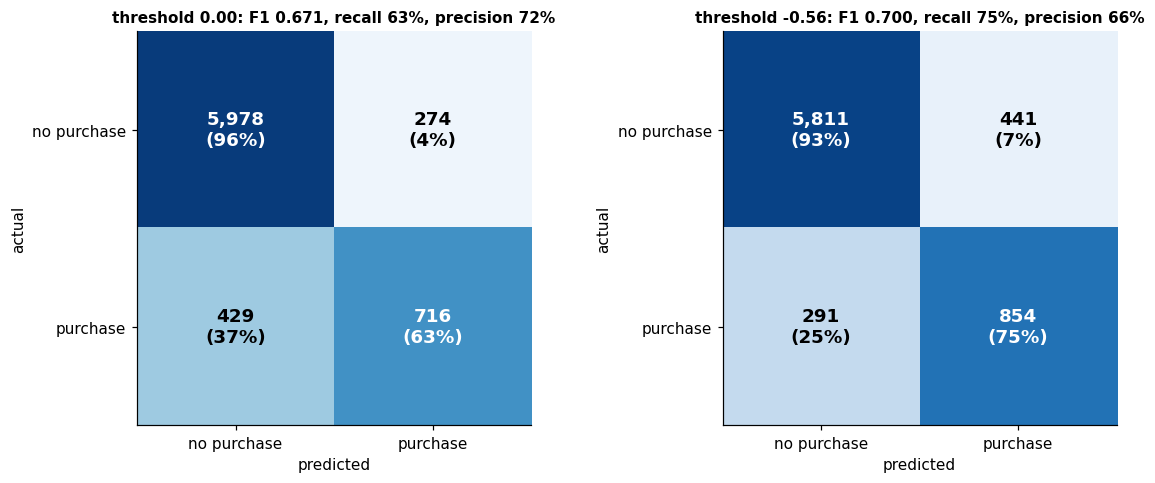

In [11]:
plot_confusion(svm_oof, [svm_default_thr, svm_thr])

# Gradient Boosting

Gradient boosting builds many small decision trees one after another. Each new tree is fitted to the mistakes the trees before it still make, and its contribution is shrunk by the learning rate.

Settings searched:

- **n_estimators**: how many trees. More trees fit the training data more closely.
- **learning_rate**: how much each tree contributes. Smaller steps need more trees but usually generalize better.
- **max_depth**: how deep each tree is. Shallow trees (2 to 3) capture simple effects; deeper trees capture interactions but memorize more easily.
- **subsample**: share of training rows each tree sees. Below 1.0 adds randomness, which acts as regularization.

### Default gradient boosting

In [12]:
results.append(evaluate("Gradient boosting, default", tree_prep, GradientBoostingClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"SVM, default",0.667,0.904,0.729,0.617,0.726,0.905,0.717,0.050
"SVM, tuned",0.671,0.912,0.736,0.625,0.724,0.905,0.719,0.049
"Gradient boosting, default",0.670,0.933,0.749,0.630,0.716,0.904,0.752,0.082


### Tune gradient boosting

This grid has 36 combinations times 5 folds.

In [13]:
gb_pipe = Pipeline([("prep", tree_prep), ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))])

gb_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 1.0],
}

gb_search = GridSearchCV(gb_pipe, gb_grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
gb_search.fit(X_train, y_train)

gb_params = {k.replace("model__", ""): v for k, v in gb_search.best_params_.items()}
print("Best settings:", gb_params)
print(f"Best CV ROC-AUC: {gb_search.best_score_:.3f}")

Best settings: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 100, 'subsample': 1.0}
Best CV ROC-AUC: 0.937


In [14]:
gb_cv = pd.DataFrame(gb_search.cv_results_)
for c in ["n_estimators", "learning_rate", "max_depth", "subsample"]:
    gb_cv[c] = gb_cv[f"param_model__{c}"].astype(float)

gb_cv.sort_values("rank_test_score").head(10)[
    ["n_estimators", "learning_rate", "max_depth", "subsample", "mean_test_score", "mean_train_score"]
].rename(columns={"mean_test_score": "CV ROC-AUC", "mean_train_score": "train ROC-AUC"}).round(4).reset_index(drop=True)

,n_estimators,learning_rate,max_depth,subsample,CV ROC-AUC,train ROC-AUC
0,100.0,0.03,4.0,1.0,0.9366,0.9537
1,100.0,0.03,4.0,0.8,0.9359,0.9555
2,200.0,0.03,4.0,1.0,0.9352,0.9633
3,200.0,0.03,3.0,1.0,0.9344,0.9510
4,200.0,0.03,4.0,0.8,0.9343,0.9654
5,300.0,0.03,3.0,1.0,0.9343,0.9562
6,300.0,0.03,4.0,1.0,0.9342,0.9702
7,100.0,0.03,3.0,1.0,0.9340,0.9433
8,200.0,0.03,3.0,0.8,0.9337,0.9522
9,100.0,0.03,3.0,0.8,0.9336,0.9443


In [15]:
gb_best = GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params)
gb_best_pipe = Pipeline([("prep", tree_prep), ("model", gb_best)])

results.append(evaluate("Gradient boosting, tuned", tree_prep, gb_best))
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"SVM, default",0.667,0.904,0.729,0.617,0.726,0.905,0.717,0.050
"SVM, tuned",0.671,0.912,0.736,0.625,0.724,0.905,0.719,0.049
"Gradient boosting, default",0.670,0.933,0.749,0.630,0.716,0.904,0.752,0.082
"Gradient boosting, tuned",0.676,0.937,0.765,0.624,0.737,0.907,0.747,0.071


### Gradient boosting: out-of-fold probabilities and decision threshold

Gradient boosting outputs a real probability the threshold search is the same as the neural network notebook: every cut-off from 0.05 to 0.95.

In [16]:
gb_oof = oof_scores(gb_best_pipe)
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_true, gb_oof):.3f}")
print(f"Out-of-fold PR-AUC:  {average_precision_score(y_true, gb_oof):.3f}")

gb_default_thr = 0.5
gb_grid_thr = np.round(np.arange(0.05, 0.96, 0.01), 2)
gb_curve = threshold_table(gb_oof, gb_grid_thr)
gb_thr = gb_curve.loc[gb_curve["f1"].idxmax(), "threshold"]

pd.DataFrame([scores_at(gb_oof, gb_default_thr), scores_at(gb_oof, gb_thr)],
             index=["default", "tuned"]).round(3)

Out-of-fold ROC-AUC: 0.936
Out-of-fold PR-AUC:  0.760


,threshold,f1,precision,recall,accuracy
default,0.5,0.675,0.737,0.624,0.907
tuned,0.3,0.704,0.643,0.778,0.899


### Gradient boosting: confusion matrices

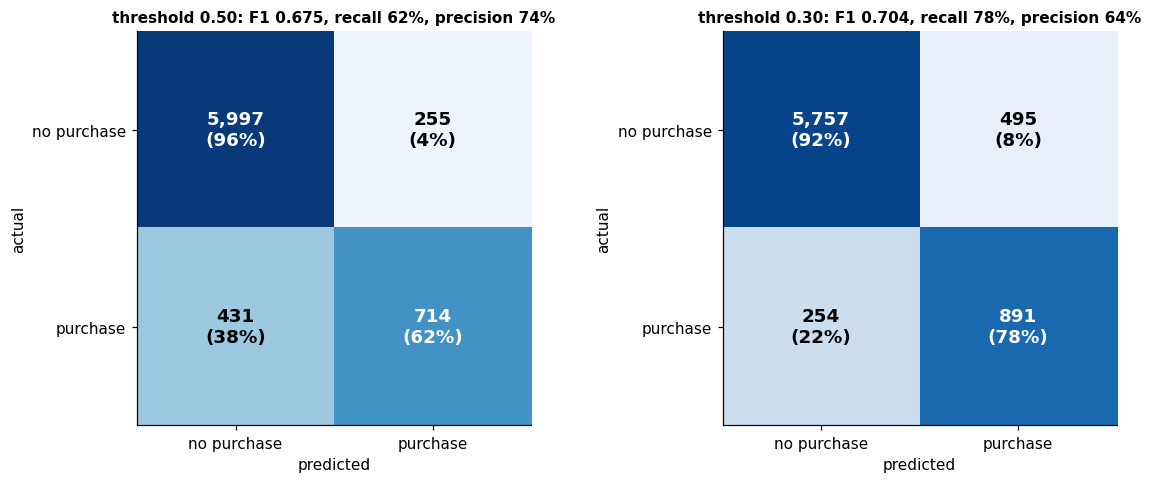

In [17]:
plot_confusion(gb_oof, [gb_default_thr, gb_thr])

# Comparison and summary

Both models side by side with the baseline.

In [18]:
res = pd.DataFrame(results).set_index("model")
res[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"SVM, default",0.667,0.904,0.729,0.617,0.726,0.905,0.717,0.050
"SVM, tuned",0.671,0.912,0.736,0.625,0.724,0.905,0.719,0.049
"Gradient boosting, default",0.670,0.933,0.749,0.630,0.716,0.904,0.752,0.082
"Gradient boosting, tuned",0.676,0.937,0.765,0.624,0.737,0.907,0.747,0.071


In [19]:
svm_summary = make_summary("SVM (RBF)", res.loc["SVM, tuned"], svm_params, svm_thr, scores_at(svm_oof, svm_thr))
gb_summary = make_summary("Gradient boosting", res.loc["Gradient boosting, tuned"], gb_params, gb_thr,
                          scores_at(gb_oof, gb_thr))
pd.concat([svm_summary, gb_summary], axis=1)

,SVM (RBF),Gradient boosting
settings,"{'C': 30, 'gamma': 0.01}","{'learning_rate': 0.03, 'max_depth': 4, 'n_est..."
CV ROC-AUC,0.912,0.937
CV PR-AUC,0.736,0.765
CV F1 @ default,0.671,0.676
train F1 @ default,0.719,0.747
best threshold,-0.563,0.3
CV F1 @ best threshold,0.7,0.704
recall @ best threshold,0.746,0.778
precision @ best threshold,0.659,0.643
